---
tags: [tutorial]
---

# Resource Estimation

When designing a quantum algorithm, it is important to know what resources it will require before running it, such as the number of qubits and gates and the circuit depth. An approximate resource estimate helps you understand what problem sizes current quantum computers can handle with the algorithm. It also lets you use current roadmaps to estimate when particular problem sizes might become feasible and compare the resource requirements of algorithms that solve the same problem. [Beverland et al.](https://arxiv.org/abs/2211.07629)

This notebook covers the basics of Qamomile's symbolic resource estimation. The `estimate_resources()` method called on a qkernel estimates the algorithm-level resources required from the structure of the qkernel, without executing the circuit. Here, algorithm-level resources **do not include** the physical qubits or gates needed to run the quantum algorithm on a particular quantum computer, or the resources required for error correction.

We use the [Greenberger–Horne–Zeilinger (GHZ) state](https://doi.org/10.1007/978-94-017-0849-4_10)

$$
|\mathrm{GHZ}_n\rangle
=\frac{|0\rangle^{\otimes n}+|1\rangle^{\otimes n}}{\sqrt2}
$$

as a common example to learn how to:

- Call `estimate_resources()` on a qkernel to perform resource estimation.
- Estimate and compare the resources required by two different implementations.
- Estimate the resources of a qkernel containing an `Oracle` with a fixed cost.
- Define costs using a callback function and estimate the resources of a qkernel containing an `Oracle` whose cost depends on its input.

In [1]:
# Install Qamomile and the packages used in this notebook.
# !pip install "qamomile[visualization]"

In [2]:
import matplotlib.pyplot as plt

import qamomile.circuit as qmc

## 1. Symbolic Resource Estimation for a GHZ State

We prepare an `n`-qubit GHZ state. We start with a simple implementation that applies `CX` gates in a chain. [Cruz et al.](https://doi.org/10.1002/qute.201900015)

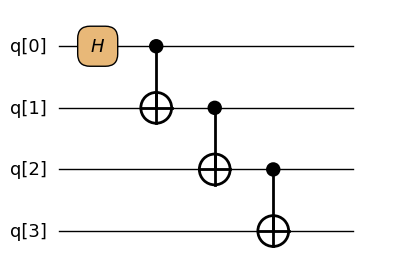

In [3]:
@qmc.qkernel
def linear_ghz(n: qmc.UInt) -> qmc.Vector[qmc.Qubit]:
    """Prepare a GHZ state with a nearest-neighbor CX chain."""
    q = qmc.qubit_array(n, "q")
    q[0] = qmc.h(q[0])
    # Use qmc.range to express a loop whose length depends on n.
    for index in qmc.range(n - 1):
        q[index], q[index + 1] = qmc.cx(q[index], q[index + 1])
    return q


linear_ghz.draw(n=4, fold_loops=False)

Leave the qubit count unspecified to get a formula in terms of `n`.

In [4]:
linear_symbolic = linear_ghz.estimate_resources()

print("=== Resource required ===")
print(f"#qubits: {linear_symbolic.width.peak_qubits}")
print(f"#single-qubit gates: {linear_symbolic.gates.single_qubit}")
print(f"#two-qubit gates: {linear_symbolic.gates.two_qubit}")
print(f"#total gates: {linear_symbolic.gates.total}")
print(f"total depth: {linear_symbolic.depth.depth}")

print()
print(f"derivation: {linear_symbolic.derivation}")
print(f"quality: {linear_symbolic.quality}")
print(f"approximation: {linear_symbolic.approximation}")
for assumption in linear_symbolic.assumptions:
    print(f"- {assumption.message}")

=== Resource required ===
#qubits: n
#single-qubit gates: 1
#two-qubit gates: n - 1
#total gates: n
total depth: n

derivation: structural
quality: exact
approximation: exact
- valid resource formula requires n >= 1 (from n)


This symbolic estimate shows that the number of qubits is $n$, the total number of gates including the Hadamard gate is $n$, and the number of CX gates is $n-1$. Since this qkernel applies a Hadamard gate to `q[0]`, the formulas are valid for $n\geq1$. Input domains like this are recorded in `assumptions` when Qamomile can identify them.

## 2. Comparing Different Implementations

The example above prepares a GHZ state using a straightforward method. Here, we prepare a GHZ state using a different implementation and compare the resources required by each implementation. In the following implementation, we set the number of qubits to $2^m$. [Cruz et al.](https://doi.org/10.1002/qute.201900015)

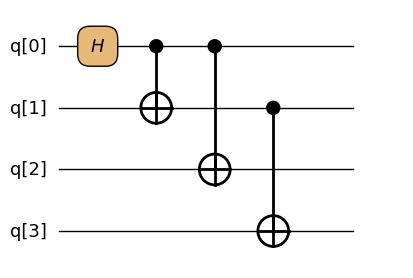

In [5]:
@qmc.qkernel
def tree_ghz(m: qmc.UInt) -> qmc.Vector[qmc.Qubit]:
    """Prepare a power-of-two GHZ state with a doubling tree."""
    size = 2**m
    q = qmc.qubit_array(size, "q")
    q[0] = qmc.h(q[0])

    for stage in qmc.range(m):
        width = 2**stage
        for control in qmc.range(width):
            target = width + control
            q[control], q[target] = qmc.cx(q[control], q[target])
    return q


tree_ghz.draw(m=2, fold_loops=False)

In [6]:
tree_symbolic = tree_ghz.estimate_resources()

print("=== Resource required ===")
print(f"#qubits: {tree_symbolic.width.peak_qubits}")
print(f"#single-qubit gates: {tree_symbolic.gates.single_qubit}")
print(f"#two-qubit gates: {tree_symbolic.gates.two_qubit}")
print(f"#total gates: {tree_symbolic.gates.total}")
print(f"total depth: {tree_symbolic.depth.depth}")

print()
print(f"derivation: {tree_symbolic.derivation}")
print(f"quality: {tree_symbolic.quality}")
print(f"approximation: {tree_symbolic.approximation}")
for assumption in tree_symbolic.assumptions:
    print(f"- {assumption.message}")

=== Resource required ===
#qubits: 2**m
#single-qubit gates: 1
#two-qubit gates: 2**m - 1
#total gates: 2**m
total depth: m + 1

derivation: structural
quality: exact
approximation: exact


We compare the resource requirements using the formulas obtained from both implementations. Here, we look at the number of quantum gates and the depth for the same number of qubits. Qamomile's resource estimates use SymPy symbols, so we can substitute values after estimation to compute concrete values without estimating the resources from the qkernel again.

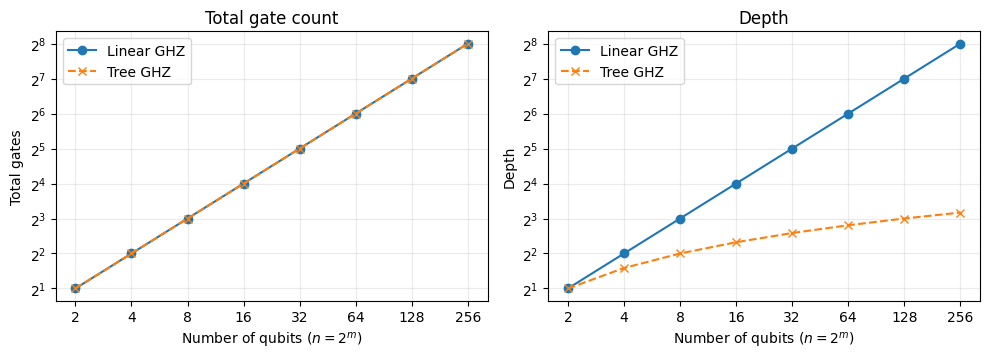

In [7]:
m_values = list(range(1, 9))
n_values = [2**m_value for m_value in m_values]

linear_resources_list = [linear_symbolic.substitute(n=n_value) for n_value in n_values]
tree_resources_list = [tree_symbolic.substitute(m=m_value) for m_value in m_values]

linear_gate_counts = [
    linear_resources.gates.total for linear_resources in linear_resources_list
]
tree_gate_counts = [
    tree_resources.gates.total for tree_resources in tree_resources_list
]
linear_gate_depths = [
    linear_resources.depth.depth for linear_resources in linear_resources_list
]
tree_gate_depths = [
    tree_resources.depth.depth for tree_resources in tree_resources_list
]

assert linear_gate_counts == tree_gate_counts == n_values
assert linear_gate_depths == n_values
assert tree_gate_depths == [m + 1 for m in m_values]

# Plot gate counts on the first axis.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
for values, label, marker, linestyle in [
    (linear_gate_counts, "Linear GHZ", "o", "-"),
    (tree_gate_counts, "Tree GHZ", "x", "--"),
]:
    axes[0].plot(
        n_values,
        values,
        marker=marker,
        linestyle=linestyle,
        label=label,
    )
# Plot circuit depths on the second axis.
for values, label, marker, linestyle in [
    (linear_gate_depths, "Linear GHZ", "o", "-"),
    (tree_gate_depths, "Tree GHZ", "x", "--"),
]:
    axes[1].plot(
        n_values,
        values,
        marker=marker,
        linestyle=linestyle,
        label=label,
    )
# Set the labels.
axes[0].set(
    xlabel=r"Number of qubits ($n=2^m$)",
    ylabel="Total gates",
    title="Total gate count",
)
axes[1].set(
    xlabel=r"Number of qubits ($n=2^m$)",
    ylabel="Depth",
    title="Depth",
)
# Configure the plots.
for axis in axes:
    axis.set_xscale("log", base=2)
    axis.set_yscale("log", base=2)
    axis.set_xticks(n_values)
    axis.set_xticklabels([str(value) for value in n_values])
    axis.grid(alpha=0.25)
    axis.legend()
# Show the plots.
plt.tight_layout()
plt.show()

The total gate counts are the same, so the curves overlap. In contrast, the depth is $n$ for the straightforward implementation and $\log_2 n+1$ for the other implementation, so the difference grows as the number of qubits increases. [Cruz et al.](https://doi.org/10.1002/qute.201900015)

## 3. Resource Estimation for a qkernel Containing an `Oracle` with a Fixed Cost

Here, we perform resource estimation using an `Oracle`. In Qamomile, an `Oracle` can be defined as a black-box operation that specifies only a cost, without an implementation. This lets users estimate the overall resources without fully implementing, for example, problem-specific operations or subroutines with several possible implementations. We first define an `Oracle` with a fixed cost and estimate the resources of a qkernel that uses it.

In [8]:
STATE_PREPARATION = "ghz_state_preparation"
fixed_linear_ghz_cost = qmc.ResourceEstimate(
    gates=qmc.GateResources(
        total=4,
        single_qubit=1,
        two_qubit=3,
        clifford=4,
    ),
    depth=qmc.DepthResources(
        depth=4,
        gate_depth=4,
        clifford_depth=4,
    ),
    calls=qmc.CallResources(calls_by_name={STATE_PREPARATION: 1}),
)
fixed_state_preparation = qmc.Oracle(
    STATE_PREPARATION,
    num_qubits=4,
    cost=fixed_linear_ghz_cost,
)

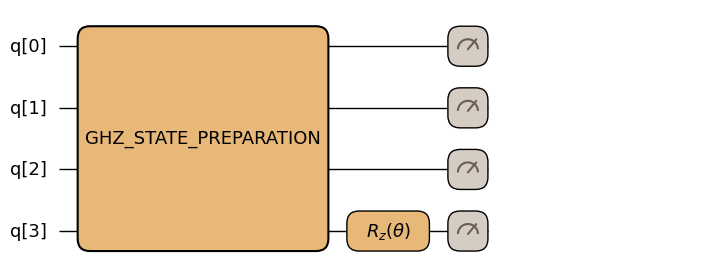

In [9]:
@qmc.qkernel
def fixed_cost_algorithm(theta: qmc.Float) -> qmc.Vector[qmc.Bit]:
    """Apply a fixed-cost state-preparation Oracle followed by an RZ gate."""
    q = qmc.qubit_array(4, "q")
    q = fixed_state_preparation(q)
    q[3] = qmc.rz(q[3], theta)
    return qmc.measure(q)


fixed_cost_algorithm.draw(fold_loops=False)

In [10]:
fixed_resources = fixed_cost_algorithm.estimate_resources()

print("=== Resource required ===")
print(f"#qubits: {fixed_resources.qubits}")
print(f"#total gates: {fixed_resources.gates.total}")
print(f"#single-qubit gates: {fixed_resources.gates.single_qubit}")
print(f"#two-qubit gates: {fixed_resources.gates.two_qubit}")
print(f"total depth: {fixed_resources.depth.depth}")
print(f"#measurements: {fixed_resources.measurements.total}")
print(f"Oracle calls: {fixed_resources.calls.oracle_calls}")

print()
print(f"Derivation: {fixed_resources.derivation.value}")
print(f"Quality: {fixed_resources.quality.value}")
print(f"Approximation: {fixed_resources.approximation.value}")
for assumption in fixed_resources.assumptions:
    print(f"- {assumption.message}")

assert fixed_resources.gates.total == 5
assert fixed_resources.measurements.total == 4

=== Resource required ===
#qubits: 4
#total gates: 5
#single-qubit gates: 2
#two-qubit gates: 3
total depth: 6
#measurements: 4
Oracle calls: {'ghz_state_preparation': 1}

Derivation: modeled
Quality: conservative
Approximation: exact
- aggregate latency may over-serialize a later wire dependency and therefore overestimate depth


The resource estimate above includes the fixed cost assigned to the `Oracle`. Because the qkernel contains an `Oracle`, `Derivation` is recorded as `MODELED`. `Quality` is `CONSERVATIVE`. This is because the gate following the `Oracle` acts on one of its qubits. An `Oracle` lets you specify its depth, but not its implementation or the order of its operations. Therefore, subsequent gates acting on qubits used by the `Oracle` are conservatively counted as starting after the depth specified for the `Oracle`, and `Quality` becomes `CONSERVATIVE`.

## 4. Specifying Input-Dependent Costs with a Callback

In the example above, we defined a fixed cost for the `Oracle`. In some cases, such as the state preparation used here, we may want to specify an `Oracle` cost that depends on the input size rather than a fixed resource cost. Qamomile supports this through a callback function. The callback receives an `OpaqueCostContext` instance and returns a `ResourceEstimate`. Users can access the number of input qubits through `OpaqueCostContext`. Below, we construct an `Oracle` using a callback function and estimate the resources of a qkernel containing this `Oracle`.

In [11]:
def linear_ghz_cost(
    context: qmc.OpaqueCostContext,
) -> qmc.ResourceEstimate:
    """Model one linear GHZ state-preparation application."""
    target_qubits = context.target_qubits
    return qmc.ResourceEstimate(
        gates=qmc.GateResources(
            total=target_qubits,
            single_qubit=1,
            two_qubit=target_qubits - 1,
            clifford=target_qubits,
        ),
        depth=qmc.DepthResources(
            depth=target_qubits,
            gate_depth=target_qubits,
            clifford_depth=target_qubits,
        ),
        calls=qmc.CallResources(
            calls_by_name={STATE_PREPARATION: 1},
        ),
        control_decomposition=context.control_decomposition,
    )


callback_state_preparation = qmc.Oracle(
    STATE_PREPARATION,
    signature=qmc.CallableSignature(
        inputs=[qmc.Vector[qmc.Qubit]],
        outputs=[qmc.Vector[qmc.Qubit]],
    ),
    cost=linear_ghz_cost,
)

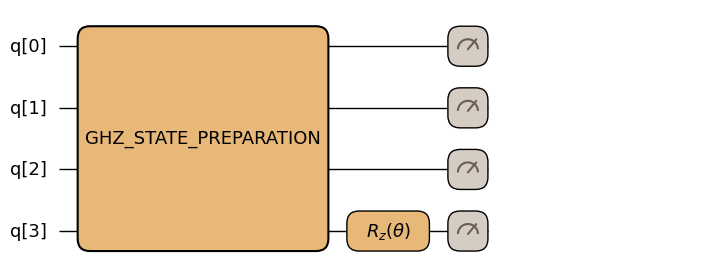

In [12]:
@qmc.qkernel
def callback_algorithm(n: qmc.UInt, theta: qmc.Float) -> qmc.Vector[qmc.Bit]:
    """Estimate an algorithm with a callback-based state-preparation cost."""
    q = qmc.qubit_array(n, "q")
    q = callback_state_preparation(q)
    q[n - 1] = qmc.rz(q[n - 1], theta)
    return qmc.measure(q)


callback_algorithm.draw(n=4)

In [13]:
callback_resources = callback_algorithm.estimate_resources()

print("=== Resource required ===")
print(f"#qubits: {callback_resources.qubits}")
print(f"#total gates: {callback_resources.gates.total}")
print(f"#single-qubit gates: {callback_resources.gates.single_qubit}")
print(f"#two-qubit gates: {callback_resources.gates.two_qubit}")
print(f"total depth: {callback_resources.depth.depth}")
print(f"Oracle calls: {callback_resources.calls.oracle_calls}")

print()
print(f"Derivation: {callback_resources.derivation.value}")
print(f"Quality: {callback_resources.quality.value}")
print(f"Approximation: {callback_resources.approximation.value}")
for assumption in callback_resources.assumptions:
    print(f"- {assumption.message}")

for width in (4, 8):
    estimate = callback_resources.substitute(n=width)
    assert estimate.gates.total == width + 1
    assert estimate.calls.oracle_calls[STATE_PREPARATION] == 1

=== Resource required ===
#qubits: n
#total gates: n + 1
#single-qubit gates: 2
#two-qubit gates: n - 1
total depth: n + 2
Oracle calls: {'ghz_state_preparation': 1}

Derivation: modeled
Quality: conservative
Approximation: exact
- aggregate latency may over-serialize a later wire dependency and therefore overestimate depth
- valid resource formula requires n - 1 >= 0 (from n)


The resource estimate above includes the cost assigned to the `Oracle`, which depends on the number of input qubits $n$. As in the fixed-cost example, because the qkernel contains an `Oracle`, `Derivation` is recorded as `MODELED`. In this example, `Quality` is recorded as `CONSERVATIVE` because an RZ gate is applied after the `Oracle` to a qubit used by the `Oracle`.

## Summary

We called `estimate_resources` on qkernels to perform symbolic resource estimation without specifying concrete input values. We then substituted concrete values into the resource estimation formulas obtained from two different implementations, evaluating the formulas without rebuilding or reevaluating the qkernels, and compared the resources required by the two implementations. Finally, we defined fixed and parameterized costs for `Oracle` objects and examined the resource estimates of qkernels that use them, confirming that the costs specified for the `Oracle` objects are reflected in the results.

Adapted from the [QCE 2026 tutorial](https://github.com/Jij-Inc/Qamomile-QCE2026-Tutorial/blob/main/docs/tutorials/en/02_resource_estimation.ipynb).